In [5]:
import numpy as np;
import pandas as pd;
import matplotlib.pyplot as plt;
import seaborn as sns;
from urllib.parse import urlparse

In [6]:
df = pd.read_csv('./Data/data.csv', encoding_errors='replace')


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 621582 entries, 0 to 621581
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   url     621582 non-null  str  
 1   Type    621582 non-null  str  
dtypes: str(2)
memory usage: 48.3 MB


In [8]:
df.columns

Index(['url', 'Type'], dtype='str')

In [9]:
df.shape

(621582, 2)

In [10]:
df.isna().sum()

url     0
Type    0
dtype: int64

In [11]:
df.drop_duplicates(inplace=True)
df.shape

(619963, 2)

In [12]:
df.isnull().sum()

url     0
Type    0
dtype: int64

In [13]:
df['Type'].value_counts()

Type
legitimate    444181
Phishing      175782
Name: count, dtype: int64

In [14]:
df['isHTTP'] = df['url'].apply(lambda x: 1 if x.startswith('https') else 0)

In [15]:
df['length'] = df['url'].apply(lambda x: len(x))

In [16]:
df['isSpeacialChar'] = df['url'].apply(lambda x: 1 if not x.isalnum() else 0)

In [17]:
import ipaddress
def extract_tld(url):
    try:
        hostname = urlparse(url).hostname or 'N/A'

        # Ignore IPv4 and IPv6 addresses
        try:
            ipaddress.ip_address(hostname)
            return ''
        except ValueError:
            parts = hostname.split('.')
            if len(parts) > 1:
                return parts[-1]
            else:
                return ''
    except (ValueError, TypeError):
        return ''

df['TLD'] = df['url'].apply(extract_tld)

In [18]:
df

,url,Type,isHTTP,length,isSpeacialChar,TLD
0,https://docs.google.com/presentation/d/e/2PACX...,Phishing,1,178,1,com
1,https://btttelecommunniccatiion.weeblysite.com/,Phishing,1,47,1,com
2,https://kq0hgp.webwave.dev/,Phishing,1,27,1,dev
3,https://brittishtele1bt-69836.getresponsesite....,Phishing,1,50,1,com
4,https://bt-internet-105056.weeblysite.com/,Phishing,1,42,1,com
...,...,...,...,...,...,...
621577,http://centerforanxietyanddepression.com/,legitimate,0,41,1,com
621578,http://www.alphanet.org/,legitimate,0,24,1,org
621579,http://www.ccbdmd.com/,legitimate,0,22,1,com
621580,http://www.alpineresearch.com/,legitimate,0,30,1,com


In [19]:
df['isDot'] = df['url'].apply(lambda x: sum(1 for c in x if c == '.'))
df['isDash'] = df['url'].apply(lambda x: sum(1 for c in x if c == '-'))
df['isSlash'] = df['url'].apply(lambda x: sum(1 for c in x if c == '/'))
df['isQuestionMark'] = df['url'].apply(lambda x: sum(1 for c in x if c == '?'))
df['isEqual'] = df['url'].apply(lambda x: sum(1 for c in x if c == '='))  
df['isNumber'] = df['url'].apply(lambda x: sum(1 for c in x if c.isdigit()))
df['isChar'] = df['url'].apply(lambda x: sum(1 for c in x if c.isalpha()))

In [20]:
from urllib.parse import urlparse, parse_qsl

def extract_structure_features(url):
    url = str(url).strip()

    try:
        parsed = urlparse(url if "://" in url else f"//{url}")
        path = parsed.path or ""
        query = parsed.query or ""
    except ValueError:
        path = ""
        query = ""

    return pd.Series({
        "path_depth": sum(bool(part) for part in path.split("/")),
        "query_param_count": len(
            parse_qsl(query, keep_blank_values=True)
        ),
    })

new_features = df["url"].apply(extract_structure_features)
df = pd.concat([df, new_features], axis=1)

df[["url", "path_depth", "query_param_count"]].head()

,url,path_depth,query_param_count
0,https://docs.google.com/presentation/d/e/2PACX...,5,4
1,https://btttelecommunniccatiion.weeblysite.com/,0,0
2,https://kq0hgp.webwave.dev/,0,0
3,https://brittishtele1bt-69836.getresponsesite....,0,0
4,https://bt-internet-105056.weeblysite.com/,0,0


<Axes: xlabel='Type', ylabel='count'>

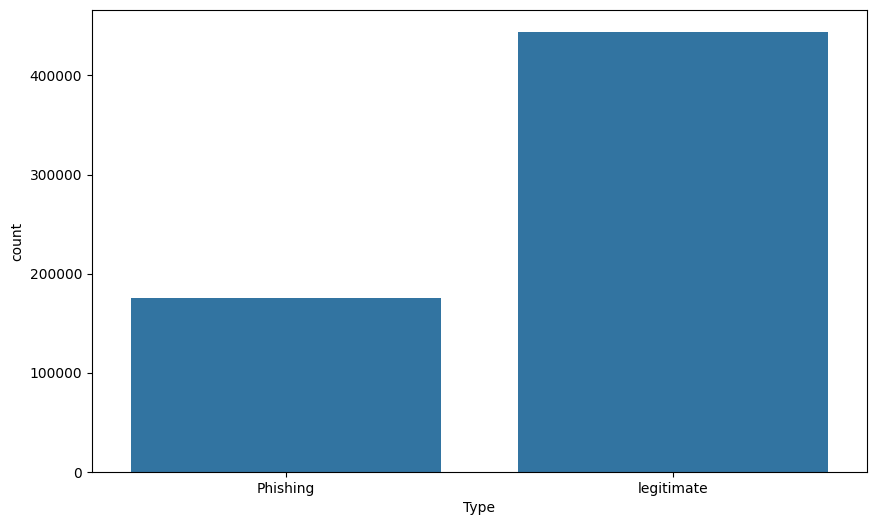

In [21]:
plt.figure(figsize=(10, 6))
sns.countplot(x='Type', data=df)


([<matplotlib.patches.Wedge at 0x1f2faa67b60>,
 [Text(-0.7195875138420087, 0.8319818567268622, '1'),
  Text(0.7195877849360696, -0.8319816222554445, '0')],
 [Text(-0.39250228027745926, 0.45380828548737934, '72.7%'),
  Text(0.39250242814694697, -0.45380815759387877, '27.3%')])

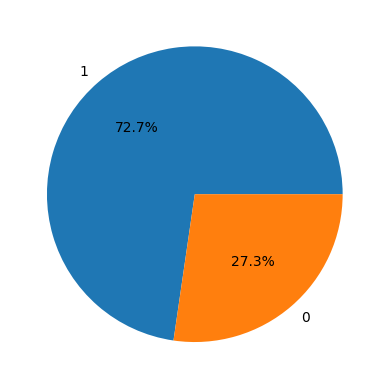

In [22]:
plt.pie(df['isHTTP'].value_counts(), labels=df['isHTTP'].value_counts().index, autopct='%1.1f%%')

In [23]:
from sklearn.preprocessing import OneHotEncoder,TargetEncoder,LabelEncoder,StandardScaler
from sklearn.model_selection import train_test_split,StratifiedKFold,GridSearchCV

In [24]:
# Calculate the frequency of each TLD
tld_frequency = df['TLD'].value_counts(normalize=True)

# Encode the TLD column
df['TLD_Frequency'] = df['TLD'].map(tld_frequency)

# Drop the original column if no longer required
df.drop(columns=['TLD'], inplace=True)

In [25]:
std = ['length','isNumber','isChar','isDot','isDash','isSlash','isQuestionMark','isEqual','path_depth','query_param_count']


In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

preprocessing = ColumnTransformer([
    ('StandardScaler', StandardScaler(), std)],remainder='passthrough')


In [27]:
preprocessing

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('StandardScaler', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.

In [28]:
X = df.drop(['url','Type'], axis=1)
y = df['Type']


In [29]:
xTrain, xTest, yTrain, yTest = train_test_split(X, y, test_size=0.2, random_state=42, stratify=df['Type'])

In [30]:
xTrainEncoder = preprocessing.fit_transform(xTrain)
xTestEncoder = preprocessing.transform(xTest)

In [31]:
del LabelEncoder

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

yTrainEncoder = label_encoder.fit_transform(yTrain)
yTestEncoder = label_encoder.transform(yTest)

In [32]:
from sklearn.ensemble import RandomForestClassifier 
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score,f1_score,precision_score,recall_score

model = RandomForestClassifier(n_estimators=100, random_state=42,class_weight='balanced')
model.fit(xTrainEncoder, yTrainEncoder)
yPred = model.predict(xTestEncoder)
model_accuracy = accuracy_score(yTestEncoder, yPred)
model_f1 = f1_score(yTestEncoder, yPred)
model_classification_report = classification_report(yTestEncoder, yPred)
    
print("Accuracy:", model_accuracy)
print("F1 Score:", model_f1)
print("Classification Report:")
print(model_classification_report)


Accuracy: 0.944553321558475
F1 Score: 0.9612922477521353
Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.90      0.90     35157
           1       0.96      0.96      0.96     88836

    accuracy                           0.94    123993
   macro avg       0.93      0.93      0.93    123993
weighted avg       0.94      0.94      0.94    123993



In [33]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay

sklearn.metrics._plot.confusion_matrix.ConfusionMatrixDisplay

In [34]:

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier

# Define the cross-validation strategy
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Your Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Define evaluation metrics
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

# Perform cross-validation
cv_results = cross_validate(
    rf_model,
    xTrainEncoder,
    yTrainEncoder,
    cv=skf,
    scoring=scoring,
    n_jobs=1,
    return_train_score=True
)

# Display results for each fold
for i in range(5):
    print(f"\nFold {i + 1}")
    print(f"Accuracy:  {cv_results['test_accuracy'][i]:.4f}")
    print(f"Precision: {cv_results['test_precision'][i]:.4f}")
    print(f"Recall:    {cv_results['test_recall'][i]:.4f}")
    print(f"F1-score:  {cv_results['test_f1'][i]:.4f}")
    print(f"ROC-AUC:   {cv_results['test_roc_auc'][i]:.4f}")

# Calculate average and standard deviation
print("\n========== Cross-Validation Summary ==========")

for metric in scoring:
    scores = cv_results[f'test_{metric}']

    print(
        f"{metric}: "
        f"{scores.mean():.4f} "
        f"+/- {scores.std():.4f}"
    )


Fold 1
Accuracy:  0.9493
Precision: 0.9549
Recall:    0.9753
F1-score:  0.9650
ROC-AUC:   0.9803

Fold 2
Accuracy:  0.9497
Precision: 0.9556
Recall:    0.9752
F1-score:  0.9653
ROC-AUC:   0.9810

Fold 3
Accuracy:  0.9488
Precision: 0.9545
Recall:    0.9751
F1-score:  0.9647
ROC-AUC:   0.9795

Fold 4
Accuracy:  0.9481
Precision: 0.9532
Recall:    0.9755
F1-score:  0.9642
ROC-AUC:   0.9790

Fold 5
Accuracy:  0.9488
Precision: 0.9539
Recall:    0.9757
F1-score:  0.9646
ROC-AUC:   0.9798

========== Cross-Validation Summary ==========
accuracy: 0.9489 +/- 0.0006
precision: 0.9544 +/- 0.0008
recall: 0.9753 +/- 0.0002
f1: 0.9648 +/- 0.0004
roc_auc: 0.9799 +/- 0.0007


In [35]:
import pickle

with open("random_forest_model.pkl", "wb") as file:
    pickle.dump(rf_model, file)

print("Model saved successfully!")

Model saved successfully!


In [36]:
import pickle

with open("random_forest_model.pkl", "rb") as file:
    rf_model = pickle.load(file)

print("Model loaded successfully!")

Model loaded successfully!
